<a href="https://colab.research.google.com/github/AlejandroMev/Data-Scientist/blob/AutoMachine-Learning/5_Resultados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Automatic ML - DS_C8_SC1_T4**

---


In [ ]:
import pandas as pd

1. Leer en un dataframe, `apps`, el contenido del archivo GooglePlayStore.csv, que almacena información de las aplicaciones móviles para los dispositivos con sistema operativo Android.

In [ ]:
apps = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TLG/AutoML/DS_C8_SC1_T4_Pruebate/GooglePlayStore.csv")
apps

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10835,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10836,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1,4.1 and up
10837,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1,2.2 and up
10838,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device


2.	 Borra todos los registros que contengan valores faltantes y las columnas que no aportan a la predicción (`App`, `Last Updated`, `Current Ver`)

In [ ]:
apps.dropna(inplace=True)
apps.isnull().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

In [ ]:
apps.drop(['App','Last Updated','Current Ver'],axis=1,inplace=True)

3.Inicia una instancia de H2O y convierte el dataframe de Pandas a H2OFrame.


In [ ]:
!pip install -U h2o
import h2o
from h2o.automl import H2OAutoML

In [ ]:
h2o.init()

Checking whether there is an H2O instance running at http://localhost:54321 . connected.


H2O_cluster_uptime:,5 hours 48 mins
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.36.0.4
H2O_cluster_version_age:,5 days
H2O_cluster_name:,H2O_from_python_unknownUser_smwkzv
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,2.221 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"


In [ ]:
appsH2O = h2o.H2OFrame(apps)

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


4. Divide `appsH2O` en conjuntos de entrenamiento y prueba, considerando una distribución 70:30 e indica que la variable de respuesta o salida será `Rating`

In [ ]:
train, test = appsH2O.split_frame(ratios=[0.70], destination_frames=['train', 'test'])

In [ ]:
y = 'Rating'
X = list(appsH2O.columns)
X.remove(y)

5.	Configura el AutoML considerando 10 pliegues para la validación cruzada y 3 minutos máximos para la generación de modelos. Ejecuta el entrenamiento, indicando que la tabla de clasificación se construirá usando el conjunto de prueba.

In [ ]:
aml = H2OAutoML(max_runtime_secs=180, nfolds=10)
aml.train(x = X, y = y, training_frame = train, leaderboard_frame=test)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
Model Details
H2OStackedEnsembleEstimator :  Stacked Ensemble
Model Key:  StackedEnsemble_AllModels_1_AutoML_6_20220404_234709

No model summary for this model

ModelMetricsRegressionGLM: stackedensemble
** Reported on train data. **

MSE: 0.09141847230707315
RMSE: 0.302354878093728
MAE: 0.20913227831488
RMSLE: 0.07027155542496154
R^2: 0.6450653989214796
Mean Residual Deviance: 0.09141847230707315
Null degrees of freedom: 6615
Residual degrees of freedom: 6610
Null deviance: 1704.0452267625262
Residual deviance: 604.824612783596
AIC: 2961.8868161806195

ModelMetricsRegressionGLM: stackedensemble
** Reported on cross-validation data. **

MSE: 0.2183751549984367
RMSE: 0.4673062753681323
MAE: 0.3168321935482314
RMSLE: 0.10369439245274215
R^2: 0.1521527699034425
Mean Residual Deviance: 0.2183751549984367
Null degrees of freedom: 6615
Residual degrees of freedom: 6610
Null deviance: 1704.541248248

6.	Imprime la tabla de clasificación. ¿Qué tan buenos fueron los modelos construidos en datos no vistos?

In [ ]:
aml.leaderboard

model_id,mean_residual_deviance,rmse,mse,mae,rmsle
StackedEnsemble_AllModels_1_AutoML_6_20220404_234709,0.242293,0.492233,0.242293,0.32922,0.112913
StackedEnsemble_BestOfFamily_2_AutoML_6_20220404_234709,0.242565,0.492509,0.242565,0.32952,0.112976
StackedEnsemble_BestOfFamily_4_AutoML_6_20220404_234709,0.242781,0.492728,0.242781,0.331001,0.112882
StackedEnsemble_AllModels_2_AutoML_6_20220404_234709,0.244859,0.494832,0.244859,0.332786,0.11349
StackedEnsemble_BestOfFamily_3_AutoML_6_20220404_234709,0.246903,0.496894,0.246903,0.33476,0.113897
StackedEnsemble_BestOfFamily_1_AutoML_6_20220404_234709,0.247322,0.497315,0.247322,0.334781,0.113924
XGBoost_grid_1_AutoML_6_20220404_234709_model_4,0.249402,0.499401,0.249402,0.333321,0.113591
XGBoost_3_AutoML_6_20220404_234709,0.249761,0.499761,0.249761,0.336425,0.114124
DRF_1_AutoML_6_20220404_234709,0.252108,0.502104,0.252108,0.332128,0.114491
XRT_1_AutoML_6_20220404_234709,0.253718,0.503704,0.253718,0.344743,0.114476


7. Evalúa el modelo con los datos de prueba y la métrica *r2*

In [ ]:
perf = aml.leader.model_performance(test)
perf.r2()

0.14815144219907805

8. Obtén el reporte de importancia de variables y su versión gráfica a través de un mapa de calor. ¿Cuáles son las características que más aportan a la predicción en los modelos graficados?

In [ ]:
aml.varimp()

,XGBoost_3,XGBoost_2,XGBoost_grid_1_model_3,XGBoost_grid_1_model_4,XGBoost_1,DeepLearning_grid_1_model_1,DeepLearning_1,XGBoost_grid_1_model_1,XGBoost_grid_1_model_2,GBM_grid_1_model_1,GLM_1,GBM_4,DRF_1,XRT_1,GBM_5,GBM_1,GBM_grid_1_model_2,GBM_2,GBM_3
Size,0.166436,0.128761,0.112979,0.128093,0.124359,0.664250,0.627063,0.358076,0.373487,0.456816,0.507260,0.424427,0.423789,0.475573,0.464852,0.451722,0.504216,0.480477,0.493885
Reviews,0.276927,0.354264,0.350792,0.308507,0.414658,0.001489,0.008514,0.174980,0.214494,0.047898,0.001334,0.057183,0.051399,0.040516,0.069761,0.069944,0.052979,0.061069,0.071229
Installs,0.202337,0.164063,0.181739,0.139090,0.137494,0.029919,0.055293,0.106875,0.081036,0.145123,0.130245,0.151165,0.157928,0.102240,0.139106,0.149590,0.142799,0.139032,0.104439
Price,0.045958,0.037696,0.039661,0.039726,0.036103,0.001730,0.001387,0.017350,0.022030,0.000000,0.001116,0.001211,0.003018,0.003764,0.001765,0.001427,0.000000,0.000897,0.001364
Type,0.005663,0.009622,0.002508,0.012702,0.006310,0.003294,0.004491,0.010886,0.007608,0.004496,0.013130,0.006844,0.011620,0.003159,0.007488,0.004724,0.001717,0.005153,0.006253
Content Rating,0.008406,0.022353,0.024527,0.027465,0.018687,0.009269,0.008999,0.010976,0.019215,0.001176,0.006216,0.004738,0.016518,0.010547,0.002455,0.001309,0.000606,0.002259,0.002561
Android Ver,0.074355,0.105559,0.087643,0.127130,0.093942,0.050233,0.056858,0.095267,0.086403,0.089208,0.070967,0.103083,0.114307,0.104073,0.078186,0.057122,0.060791,0.061693,0.076234
Category,0.069910,0.055902,0.034273,0.082646,0.061240,0.054060,0.058012,0.061050,0.045684,0.015218,0.084156,0.091421,0.084447,0.094379,0.061184,0.080745,0.053389,0.051006,0.072277
Genres,0.150008,0.121781,0.165880,0.134641,0.107208,0.185758,0.179383,0.164540,0.150042,0.240065,0.185575,0.159928,0.136974,0.165747,0.175204,0.183418,0.183504,0.198416,0.171758


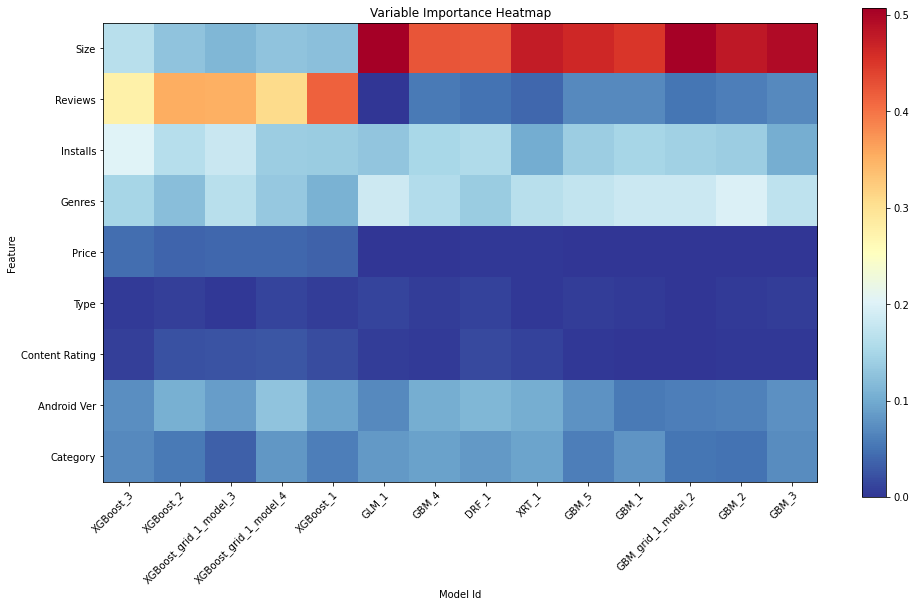

In [ ]:
aml.varimp_heatmap()

9. Utiliza la función `explain()` para generar las gráficas de análisis residual, dependencias parciales y expectativa condicional del mejor modelo



# Residual Analysis

> Residual Analysis plots the fitted values vs residuals on a test dataset. Ideally, residuals should be randomly distributed. Patterns in this plot can indicate potential problems with the model selection, e.g., using simpler model than necessary, not accounting for heteroscedasticity, autocorrelation, etc. Note that if you see "striped" lines of residuals, that is an artifact of having an integer valued (vs a real valued) response variable.

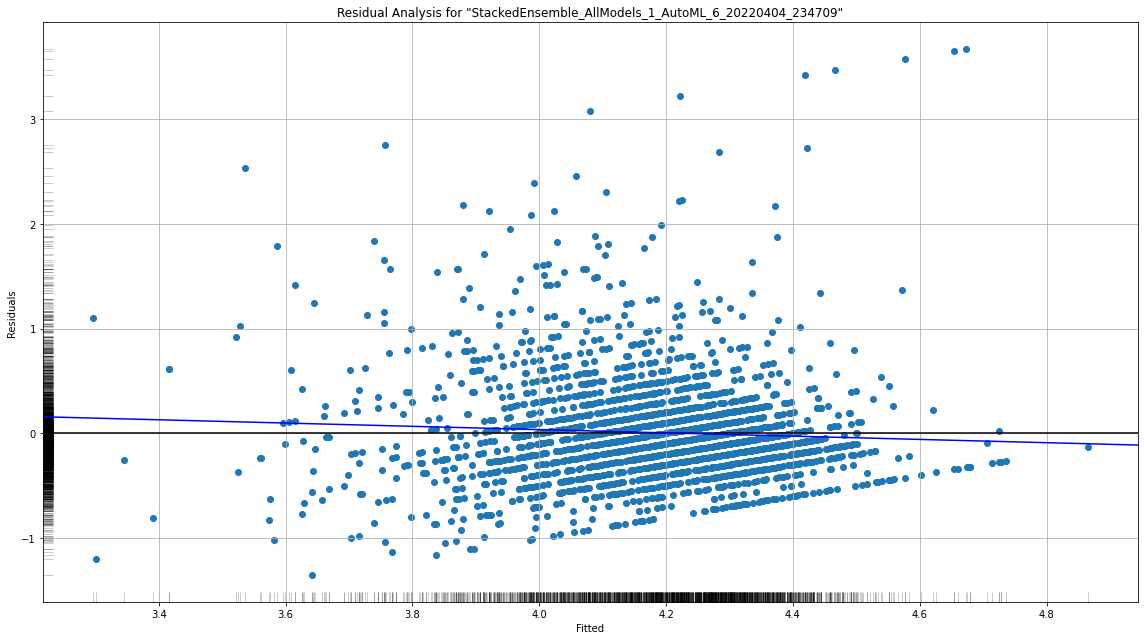

# Partial Dependence Plots

> Partial dependence plot (PDP) gives a graphical depiction of the marginal effect of a variable on the response. The effect of a variable is measured in change in the mean response. PDP assumes independence between the feature for which is the PDP computed and the rest.

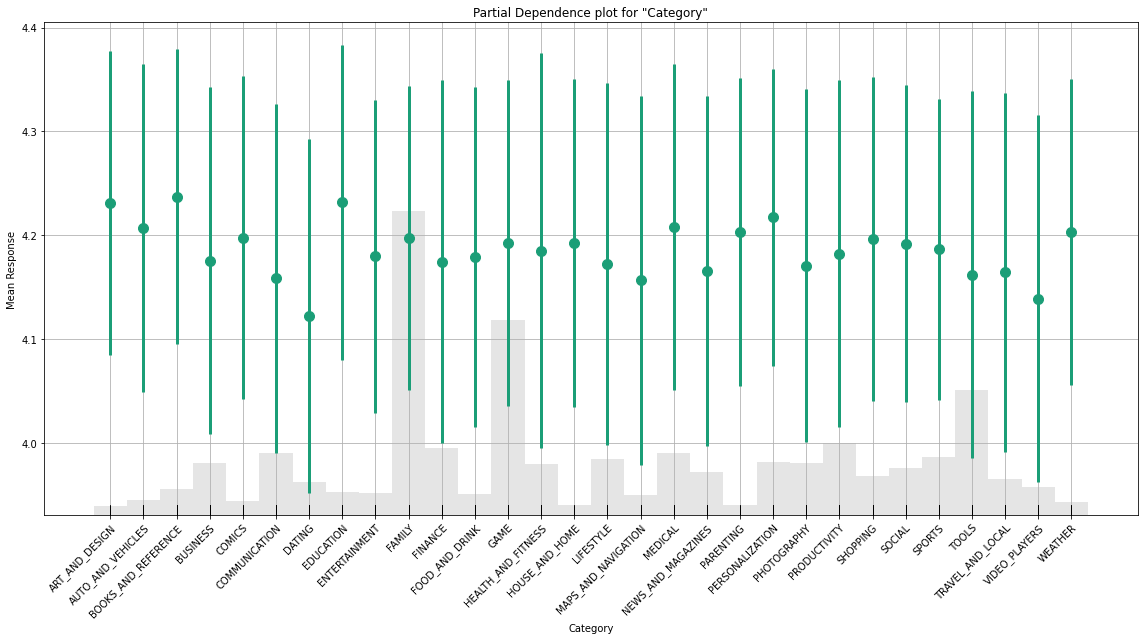

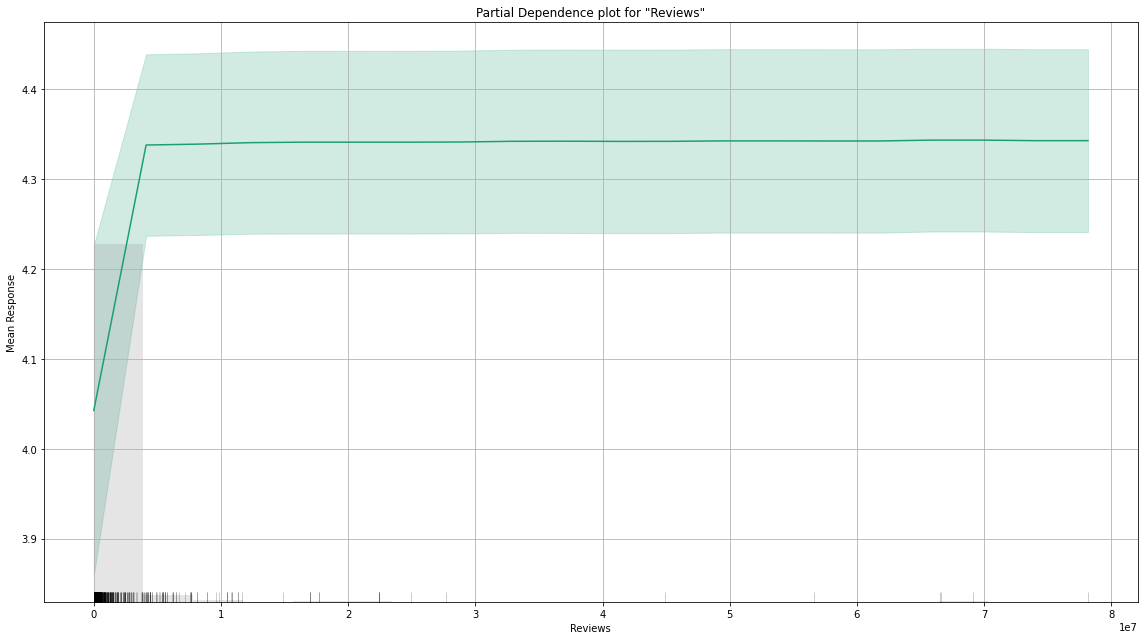

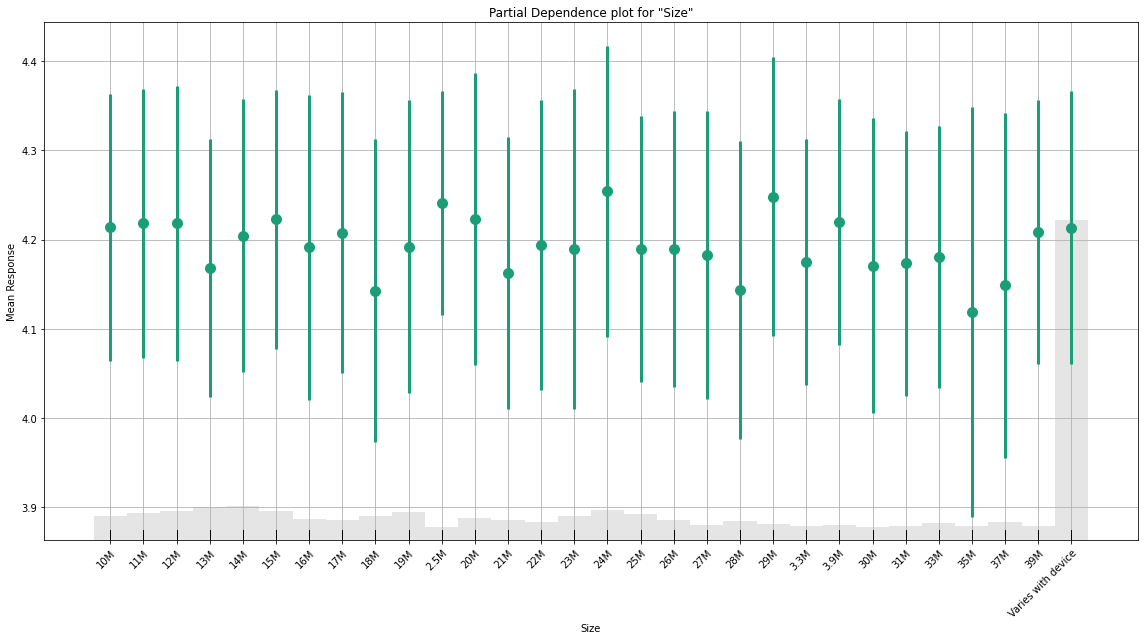

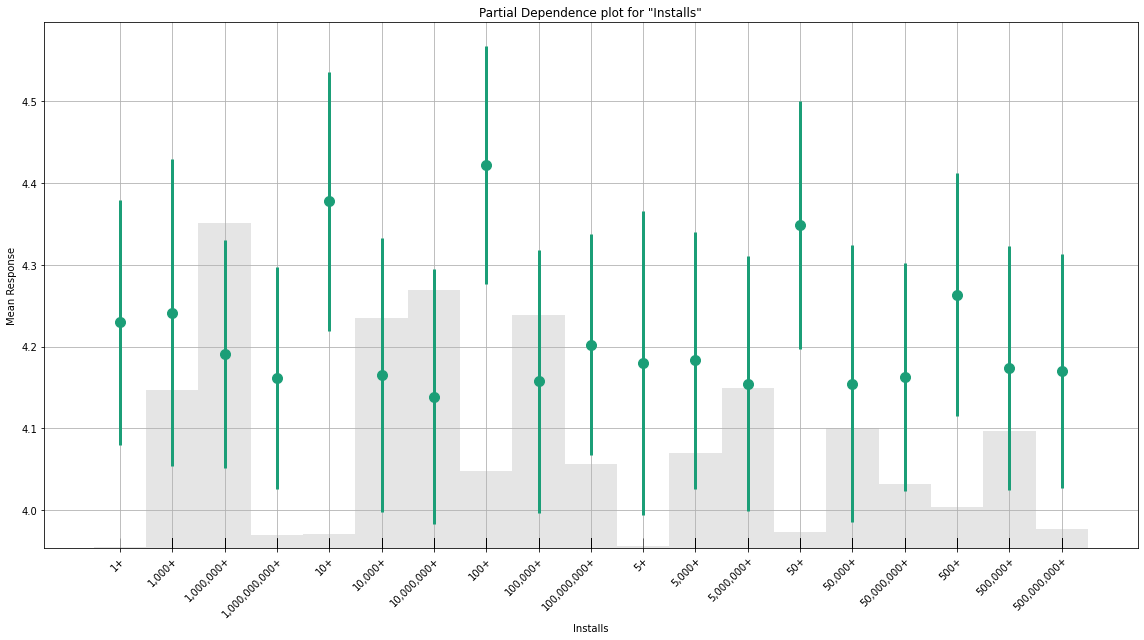

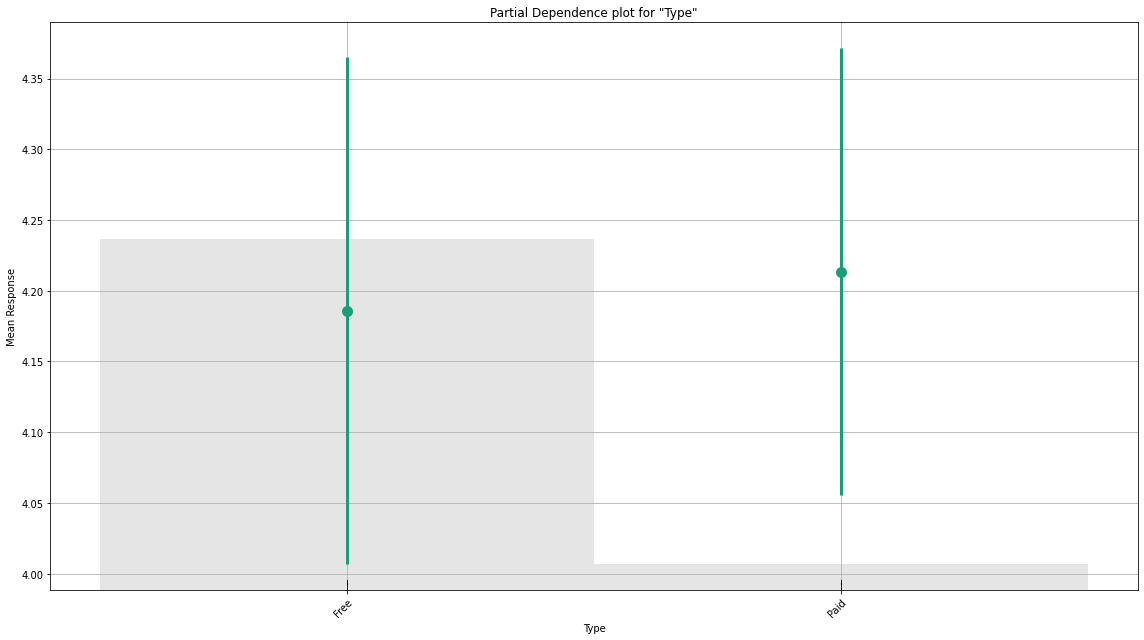

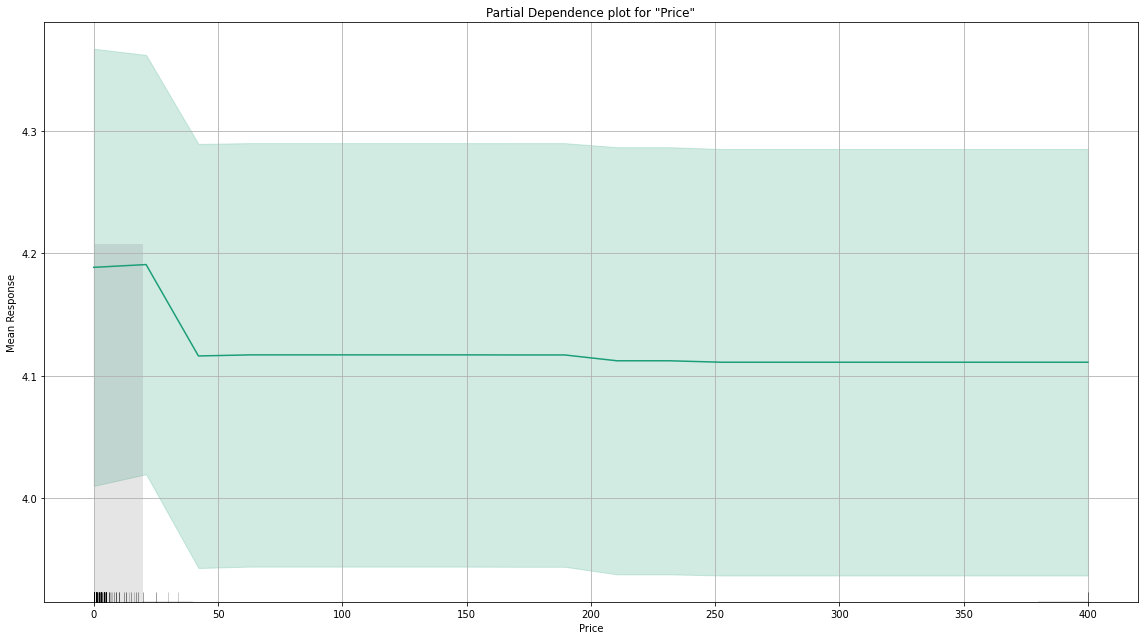

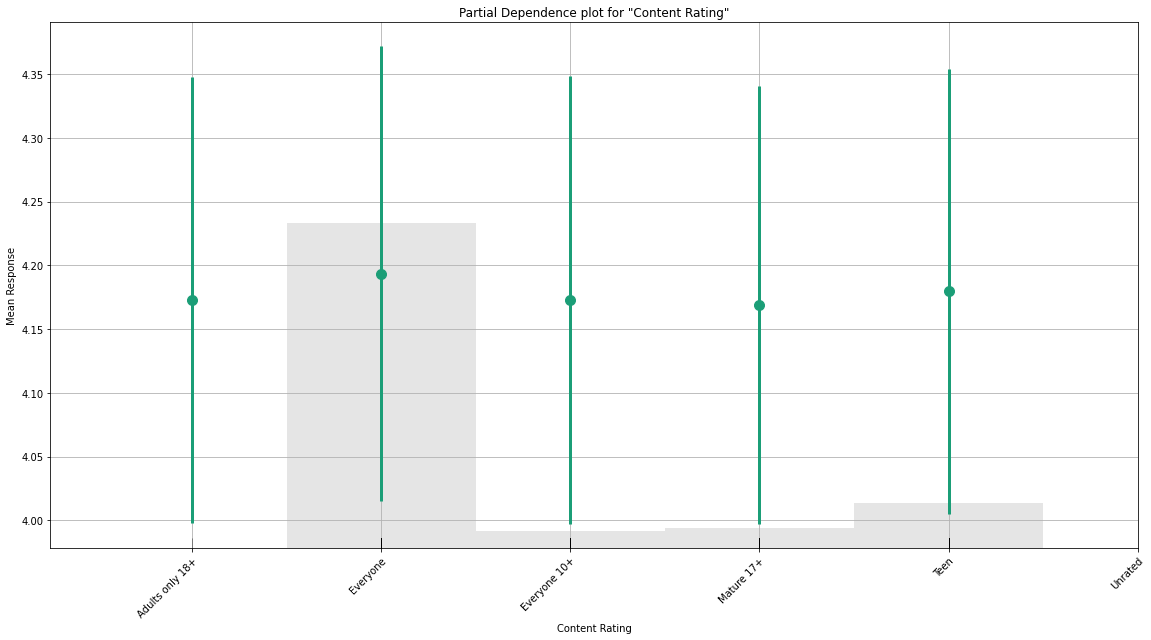

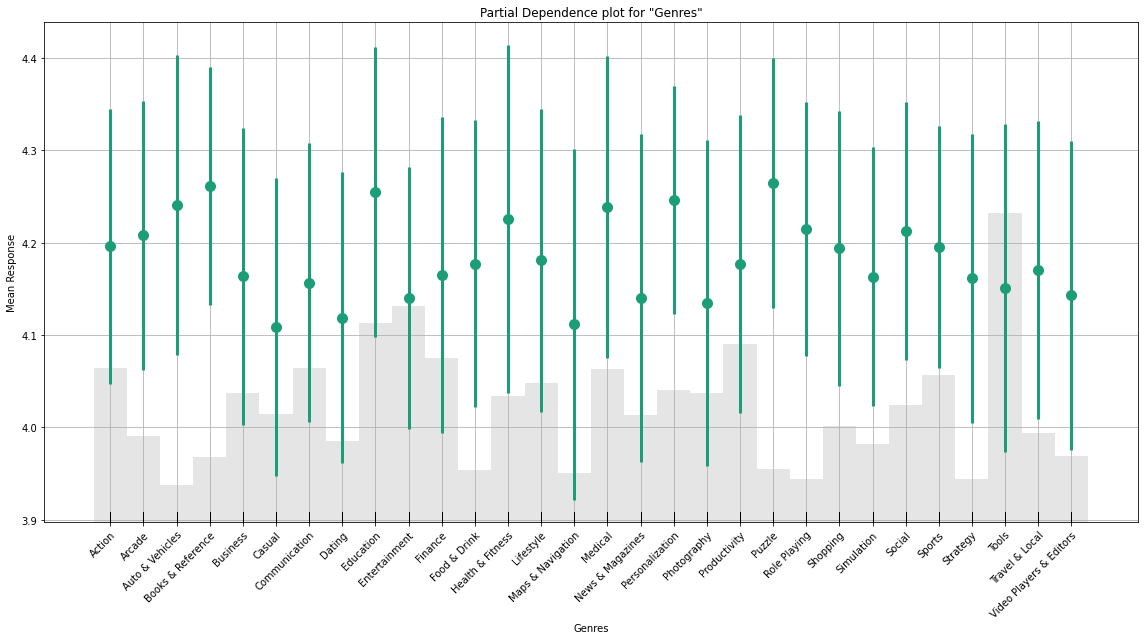

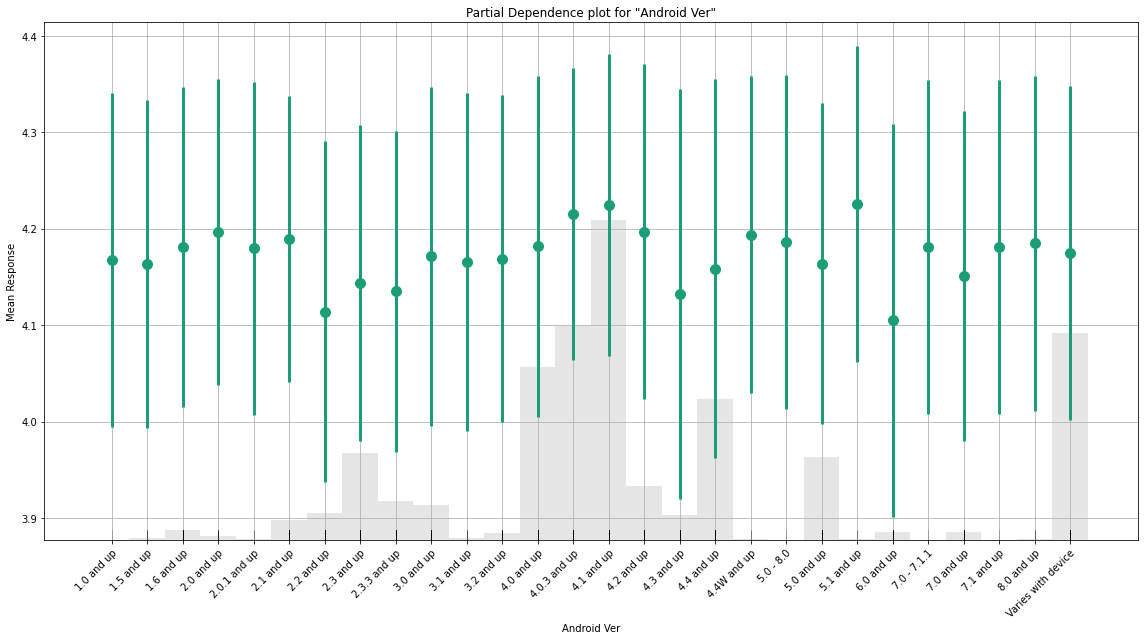

# Individual Conditional Expectation

> An Individual Conditional Expectation (ICE) plot gives a graphical depiction of the marginal effect of a variable on the response. ICE plots are similar to partial dependence plots (PDP); PDP shows the average effect of a feature while ICE plot shows the effect for a single instance. This function will plot the effect for each decile. In contrast to the PDP, ICE plots can provide more insight, especially when there is stronger feature interaction.

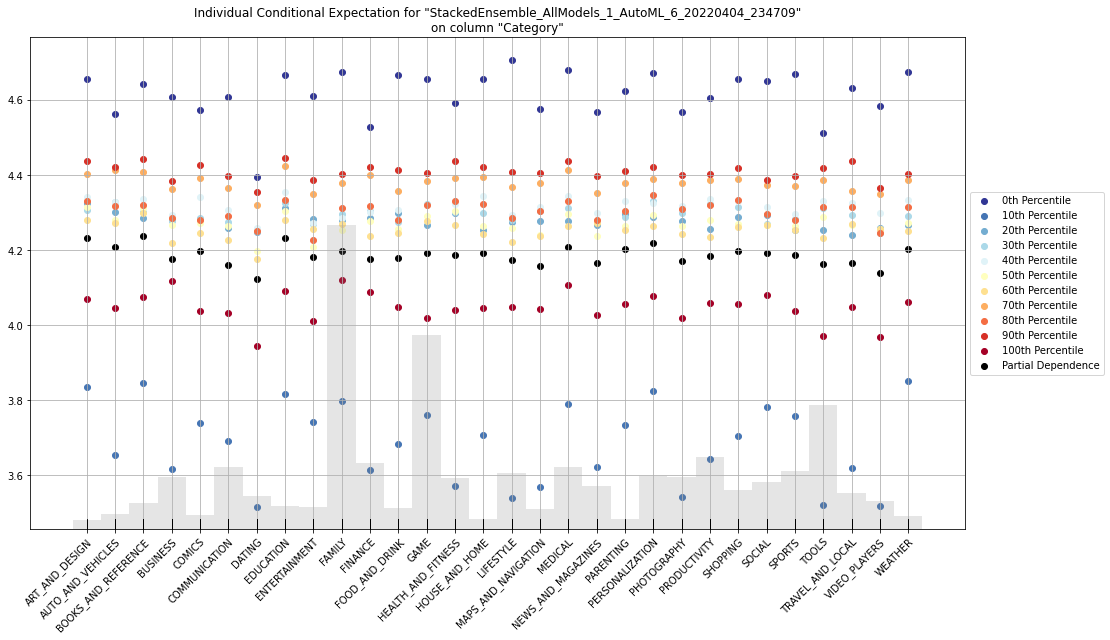

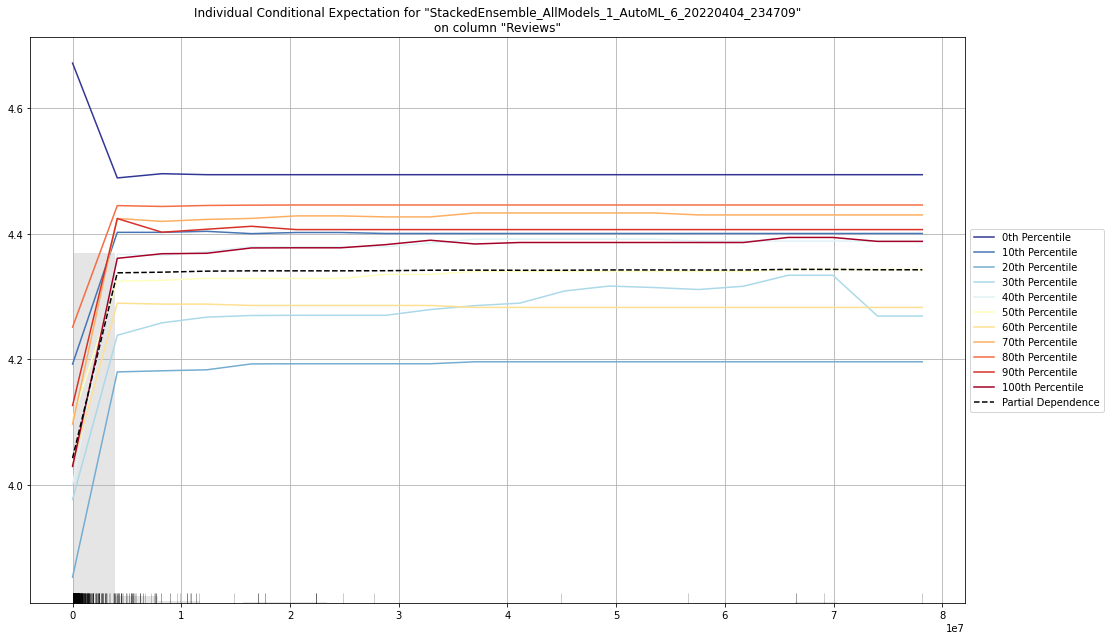

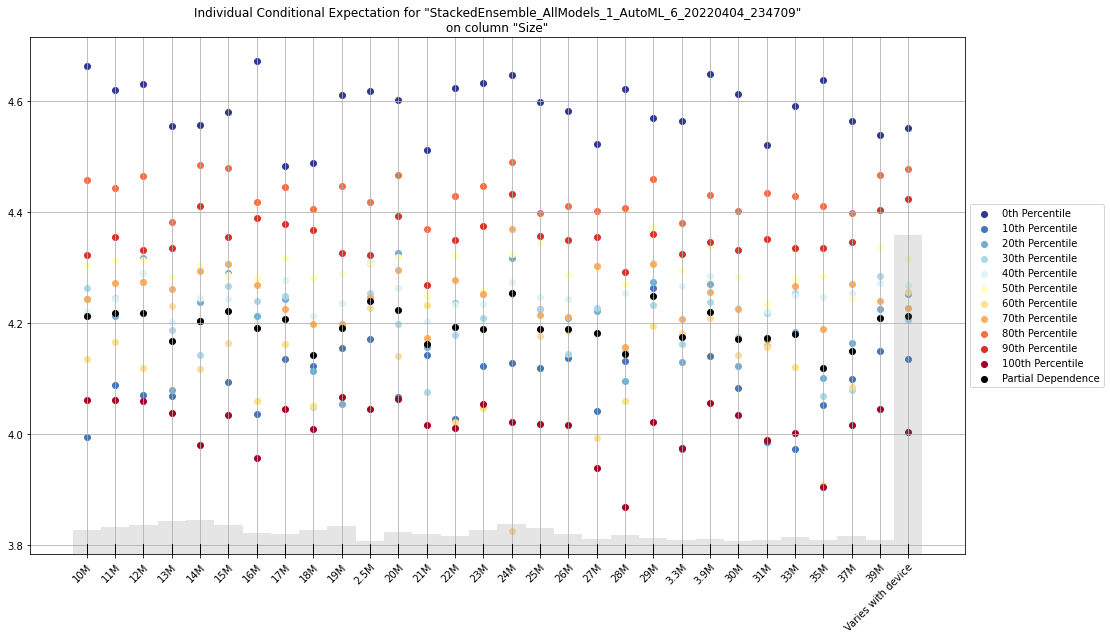

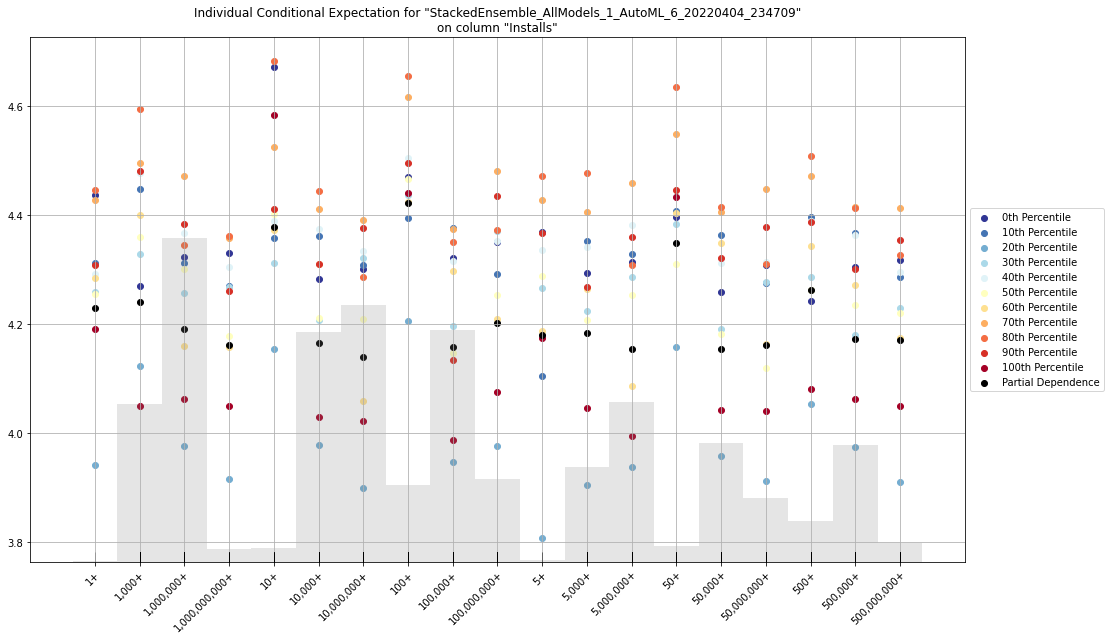

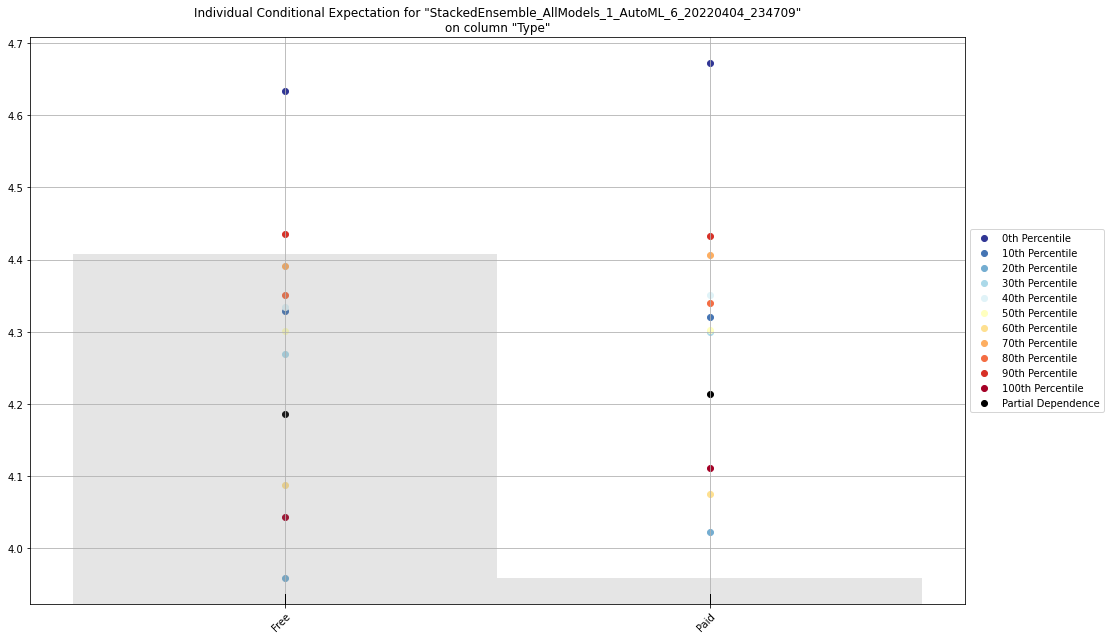

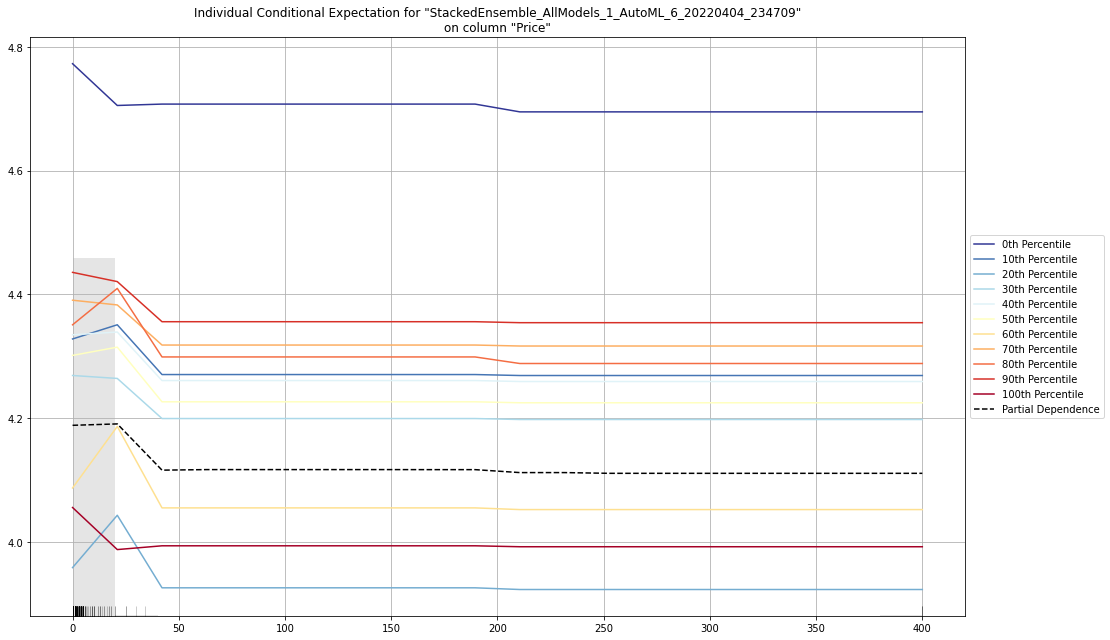

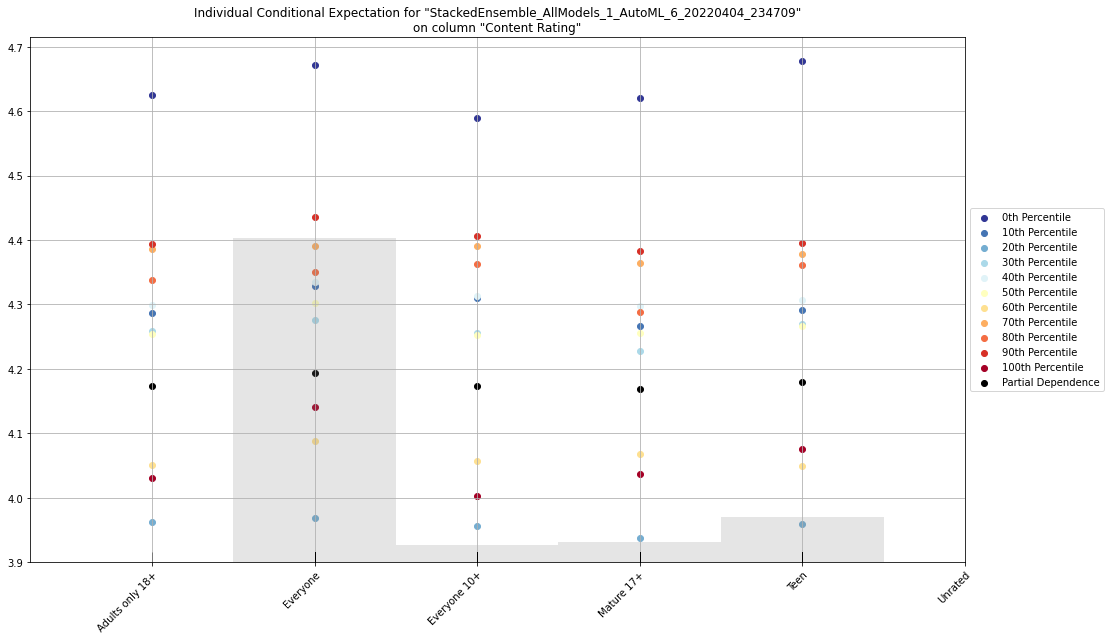

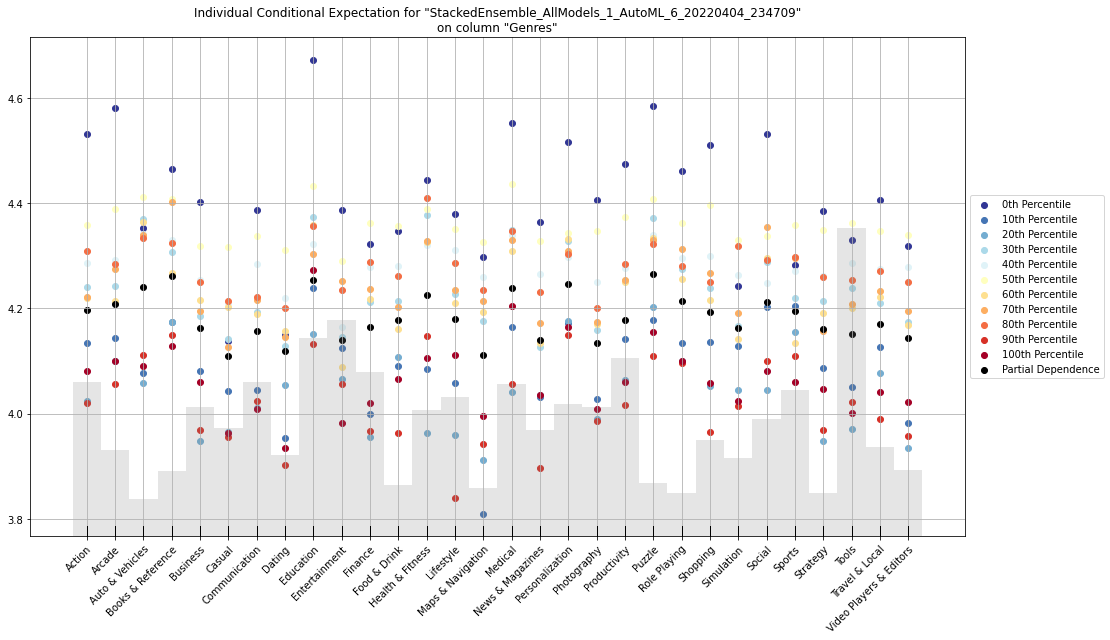

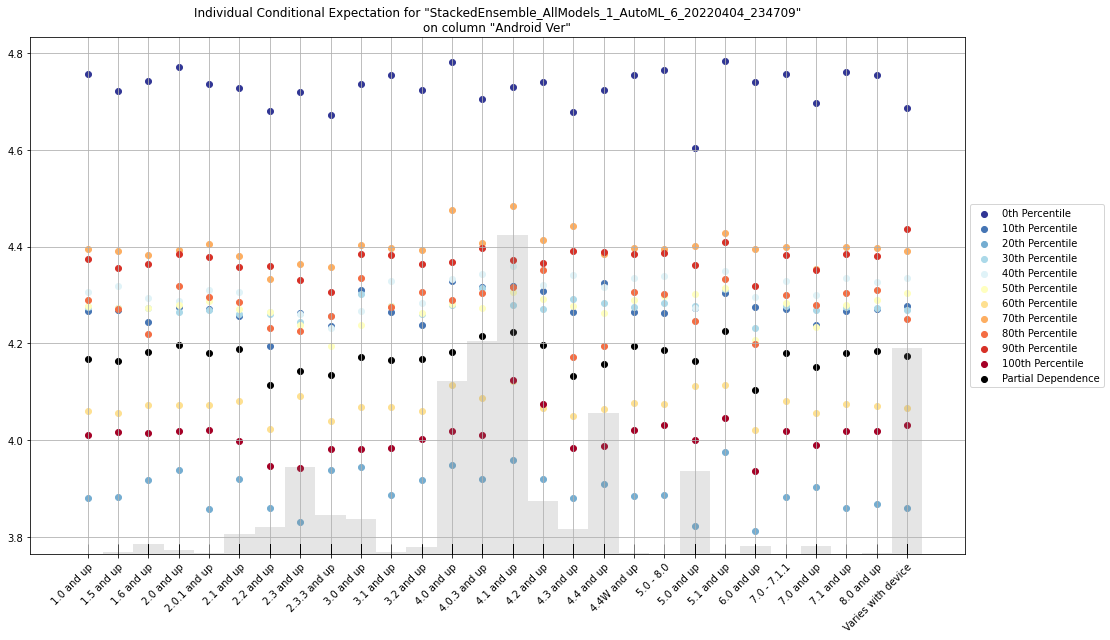

# Residual Analysis

> Residual Analysis plots the fitted values vs residuals on a test dataset. Ideally, residuals should be randomly distributed. Patterns in this plot can indicate potential problems with the model selection, e.g., using simpler model than necessary, not accounting for heteroscedasticity, autocorrelation, etc. Note that if you see "striped" lines of residuals, that is an artifact of having an integer valued (vs a real valued) response variable.

# Partial Dependence Plots

> Partial dependence plot (PDP) gives a graphical depiction of the marginal effect of a variable on the response. The effect of a variable is measured in change in the mean response. PDP assumes independence between the feature for which is the PDP computed and the rest.

# Individual Conditional Expectation

> An Individual Conditional Expectation (ICE) plot gives a graphical depiction of the marginal effect of a variable on the response. ICE plots are similar to partial dependence plots (PDP); PDP shows the average effect of a feature while ICE plot shows the effect for a single instance. This function will plot the effect for each decile. In contrast to the PDP, ICE plots can provide more insight, especially when there is stronger feature interaction.

In [ ]:
aml.leader.explain(test)